# AI4I 2020 Predictive Maintenance — Data Preprocessing & Quality Audit

**Goal:** inspect the dataset *before* any modelling. No training happens in this notebook.

**Analogy:** think of this notebook as a *pre-flight checklist*. A pilot does not skip it because the plane "looks fine" — it catches problems while they are cheap to fix.

| # | Check | Question it answers |
|---|-------|---------------------|
| 1 | Structure & dtypes | Is every column the type I expect? |
| 2 | Missing values | Is anything empty (or hiding as `0` / `?` / blank)? |
| 3 | Duplicates | Are rows or IDs repeated? |
| 4 | Class balance | How rare is a failure? |
| 5 | Label consistency | Does `Machine failure` agree with the failure-mode flags? |
| 6 | Categorical review | Are `Type` categories clean? |
| 7 | Distributions & outliers | Are values physically plausible? |
| 8 | Correlation & leakage | Which columns must **not** be used as features? |
| 9 | Preprocessing pipeline | Clean, split, encode, scale (fit on train only) |
| 10 | Export | Save the ready-to-use datasets |

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

DATA_PATH = "../data/ai4i2020.csv"      # adjust if the file lives elsewhere
RANDOM_STATE = 42

## 1. Load data & structure overview

In [3]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()   # never touch the raw frame

print("Shape:", df.shape)
df.head()

Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


### Column dictionary

| Column | Role | Notes |
|---|---|---|
| `UDI` | identifier | row index, no predictive value |
| `Product ID` | identifier | quality letter + serial number |
| `Type` | categorical feature | L / M / H quality variant |
| `Air temperature [K]`, `Process temperature [K]`, `Rotational speed [rpm]`, `Torque [Nm]`, `Tool wear [min]` | numeric features | sensor readings |
| `Machine failure` | **target** | 1 = machine failed |
| `TWF`, `HDF`, `PWF`, `OSF`, `RNF` | failure modes | **leakage risk** — they *explain* the target |

In [6]:
ID_COLS      = ["UDI", "Product ID"]
CAT_COLS     = ["Type"]
NUM_COLS     = ["Air temperature [K]", "Process temperature [K]",
                "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
TARGET       = "Machine failure"
FAILURE_MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# sanity check: every column is assigned to exactly one role
assigned = ID_COLS + CAT_COLS + NUM_COLS + [TARGET] + FAILURE_MODES
assert set(assigned) == set(df.columns), set(df.columns) ^ set(assigned)

## 2. Missing values

Two layers: **explicit** nulls (`NaN`) and **hidden** nulls (blank strings, `?`, `-`, or impossible zeros).

In [7]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(3),
})
missing

,missing_count,missing_pct
UDI,0,0.0
Product ID,0,0.0
Type,0,0.0
Air temperature [K],0,0.0
Process temperature [K],0,0.0
Rotational speed [rpm],0,0.0
Torque [Nm],0,0.0
Tool wear [min],0,0.0
Machine failure,0,0.0
TWF,0,0.0


In [8]:
print("Total explicit NaN:", int(df.isna().sum().sum()))

# hidden nulls in text columns
placeholders = {"", " ", "?", "-", "NA", "N/A", "na", "null", "NULL", "None", "nan"}
for col in df.select_dtypes(include="object").columns.tolist() + df.select_dtypes(include="string").columns.tolist():
    n = df[col].astype(str).str.strip().isin(placeholders).sum()
    print(f"{col:<15} placeholder-like values: {n}")

# hidden nulls in numeric columns: zeros that are physically implausible
print()
for col in NUM_COLS:
    z = (df[col] == 0).sum()
    print(f"{col:<26} zeros: {z}")
print("\nNote: Tool wear = 0 is legitimate (a brand-new tool); the others should never be 0.")

Total explicit NaN: 0
Product ID      placeholder-like values: 0
Type            placeholder-like values: 0
Product ID      placeholder-like values: 0
Type            placeholder-like values: 0

Air temperature [K]        zeros: 0
Process temperature [K]    zeros: 0
Rotational speed [rpm]     zeros: 0
Torque [Nm]                zeros: 0
Tool wear [min]            zeros: 120

Note: Tool wear = 0 is legitimate (a brand-new tool); the others should never be 0.


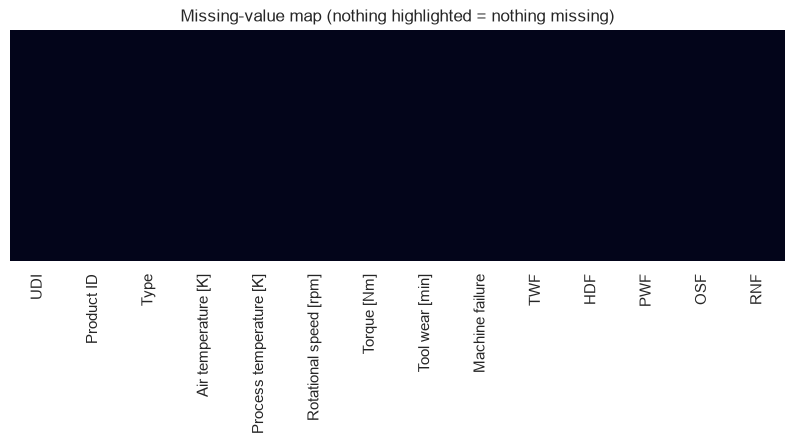

In [9]:
fig, ax = plt.subplots(figsize=(10, 3))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, ax=ax)
ax.set_title("Missing-value map (nothing highlighted = nothing missing)")
plt.show()

## 3. Duplicates

Checked at three levels: whole-row, feature-only (same sensor values, ignoring IDs), and ID columns.

In [10]:
print("Fully duplicated rows        :", df.duplicated().sum())
print("Duplicated feature vectors   :", df.duplicated(subset=NUM_COLS + CAT_COLS).sum())
print("Duplicated UDI               :", df["UDI"].duplicated().sum())
print("Duplicated Product ID        :", df["Product ID"].duplicated().sum())

Fully duplicated rows        : 0
Duplicated feature vectors   : 0
Duplicated UDI               : 0
Duplicated Product ID        : 0


In [11]:
# UDI should be a clean 1..N sequence
print("UDI is unique & sequential:", df["UDI"].is_unique and (df["UDI"].diff().dropna() == 1).all())

# Product ID prefix should agree with Type (L/M/H)
prefix_mismatch = (df["Product ID"].str[0] != df["Type"]).sum()
print("Product ID prefix != Type  :", prefix_mismatch)

UDI is unique & sequential: True
Product ID prefix != Type  : 0


In [12]:
# Same feature vector but different labels would be noise — check it
feat_cols = NUM_COLS + CAT_COLS
grp = df.groupby(feat_cols)[TARGET].nunique()
print("Feature vectors with conflicting labels:", int((grp > 1).sum()))

Feature vectors with conflicting labels: 0


## 4. Class balance (target)

**Analogy:** if 97 of 100 fire alarms are *false*, a "smart" system that never rings will be right 97% of the time and still be useless. Accuracy alone would lie to us here.

In [13]:
counts = df[TARGET].value_counts().sort_index()
pct = (df[TARGET].value_counts(normalize=True).sort_index() * 100).round(2)
balance = pd.DataFrame({"count": counts, "percent": pct})
balance.index = balance.index.map({0: "0 (no failure)", 1: "1 (failure)"})
display(balance)

ratio = counts[0] / counts[1]
print(f"Imbalance ratio (majority : minority) = {ratio:.1f} : 1")
print(f"Naive 'always predict 0' accuracy      = {counts[0] / counts.sum():.2%}")

,count,percent
Machine failure,,
0 (no failure),9661,96.61
1 (failure),339,3.39


Imbalance ratio (majority : minority) = 28.5 : 1
Naive 'always predict 0' accuracy      = 96.61%


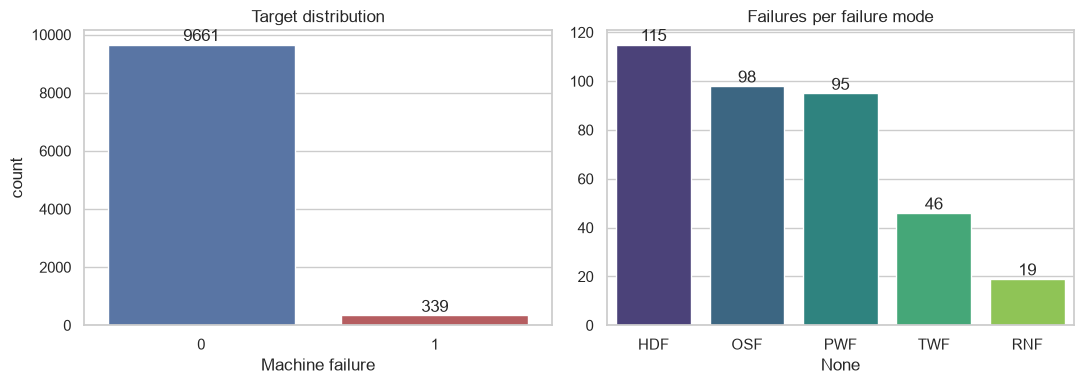

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(x=TARGET, data=df, ax=axes[0], palette=["#4c72b0", "#c44e52"])
axes[0].set_title("Target distribution")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                     ha="center", va="bottom")

fm_counts = df[FAILURE_MODES].sum().sort_values(ascending=False)
sns.barplot(x=fm_counts.index, y=fm_counts.values, ax=axes[1], palette="viridis")
axes[1].set_title("Failures per failure mode")
for i, v in enumerate(fm_counts.values):
    axes[1].text(i, v, int(v), ha="center", va="bottom")
plt.tight_layout(); plt.show()

In [15]:
# Failure rate per product Type (does imbalance differ across groups?)
type_rate = df.groupby("Type")[TARGET].agg(["count", "sum", "mean"])
type_rate.columns = ["rows", "failures", "failure_rate"]
type_rate["failure_rate"] = (type_rate["failure_rate"] * 100).round(2)
type_rate

,rows,failures,failure_rate
Type,,,
H,1003,21,2.09
L,6000,235,3.92
M,2997,83,2.77


**Takeaway for later:** the minority class is rare, so the split must be **stratified**, and evaluation should use precision / recall / F1 / PR-AUC rather than accuracy alone. Resampling (SMOTE, class weights, etc.) — if wanted — belongs in the training step and must touch **only the training split**.

## 5. Label consistency

`Machine failure` should be 1 **iff** at least one failure mode (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) is 1. Let's verify.

In [16]:
df["_any_mode"] = (df[FAILURE_MODES].sum(axis=1) > 0).astype(int)

print(pd.crosstab(df[TARGET], df["_any_mode"],
                  rownames=["Machine failure"], colnames=["Any failure mode"]))

inconsistent = df[df[TARGET] != df["_any_mode"]]
print("\nInconsistent rows:", len(inconsistent))
inconsistent.drop(columns="_any_mode").head(30)

Any failure mode     0    1
Machine failure            
0                 9643   18
1                    9  330

Inconsistent rows: 27


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
1221,1222,M16081,M,297.0,308.3,1399,46.4,132,0,0,0,0,0,1
1302,1303,L48482,L,298.6,309.8,1505,45.7,144,0,0,0,0,0,1
1437,1438,H30851,H,298.8,309.9,1439,45.2,40,1,0,0,0,0,0
1748,1749,H31162,H,298.4,307.7,1626,31.1,166,0,0,0,0,0,1
2072,2073,L49252,L,299.6,309.5,1570,35.5,189,0,0,0,0,0,1
2559,2560,L49739,L,299.3,309.0,1447,50.4,140,0,0,0,0,0,1
2749,2750,M17609,M,299.7,309.2,1685,28.9,179,1,0,0,0,0,0
3065,3066,M17925,M,300.1,309.2,1687,27.7,95,0,0,0,0,0,1
3452,3453,H32866,H,301.6,310.5,1602,32.3,2,0,0,0,0,0,1
4044,4045,M18904,M,301.9,310.9,1419,47.7,20,1,0,0,0,0,0


In [17]:
print("Rows with multiple simultaneous failure modes:", int((df[FAILURE_MODES].sum(axis=1) > 1).sum()))
print("\nInconsistent rows by type:")
print("  target=0 but a mode flag = 1 :", int(((df[TARGET] == 0) & (df["_any_mode"] == 1)).sum()))
print("  target=1 but no mode flag    :", int(((df[TARGET] == 1) & (df["_any_mode"] == 0)).sum()))
print("\nRNF (random failure) among inconsistent rows:")
print(inconsistent[FAILURE_MODES].sum())

Rows with multiple simultaneous failure modes: 24

Inconsistent rows by type:
  target=0 but a mode flag = 1 : 18
  target=1 but no mode flag    : 9

RNF (random failure) among inconsistent rows:
TWF     0
HDF     0
PWF     0
OSF     0
RNF    18
dtype: int64


> **Decision point.** The inconsistent rows are a known quirk of this dataset: rows where `RNF` (random failure) is flagged but `Machine failure` = 0, plus rows where `Machine failure` = 1 but no mode is flagged. Options: keep as-is, relabel using the failure modes, or drop them. The flag below lets you choose; the default **keeps** them and only reports.

In [18]:
DROP_INCONSISTENT = False   # set True to drop label-inconsistent rows

if DROP_INCONSISTENT:
    df = df[df[TARGET] == df["_any_mode"]].copy()
    print("Dropped inconsistent rows. New shape:", df.shape)
df = df.drop(columns="_any_mode")

## 6. Categorical review (`Type`)

In [19]:
print(df["Type"].value_counts(dropna=False))
print("\nUnique raw values:", sorted(df["Type"].unique()))

# whitespace / case problems?
clean = df["Type"].str.strip().str.upper()
print("Values changed by strip/upper:", int((clean != df["Type"]).sum()))

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Unique raw values: ['H', 'L', 'M']
Values changed by strip/upper: 0


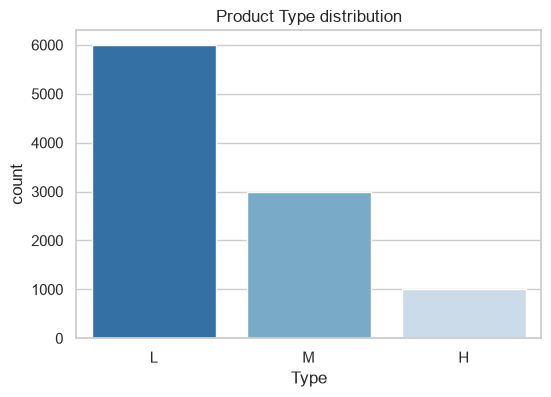

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x="Type", data=df, order=["L", "M", "H"], ax=ax, palette="Blues_r")
ax.set_title("Product Type distribution")
plt.show()

## 7. Distributions & outliers

Two lenses: the **IQR rule** (statistical outlier) and **physical plausibility** (domain sense).

In [21]:
df[NUM_COLS].describe().T[["min", "25%", "50%", "75%", "max", "mean", "std"]]

,min,25%,50%,75%,max,mean,std
Air temperature [K],295.3,298.3,300.1,301.5,304.5,300.00493,2.000259
Process temperature [K],305.7,308.8,310.1,311.1,313.8,310.00556,1.483734
Rotational speed [rpm],1168.0,1423.0,1503.0,1612.0,2886.0,1538.77610,179.284096
Torque [Nm],3.8,33.2,40.1,46.8,76.6,39.98691,9.968934
Tool wear [min],0.0,53.0,108.0,162.0,253.0,107.95100,63.654147


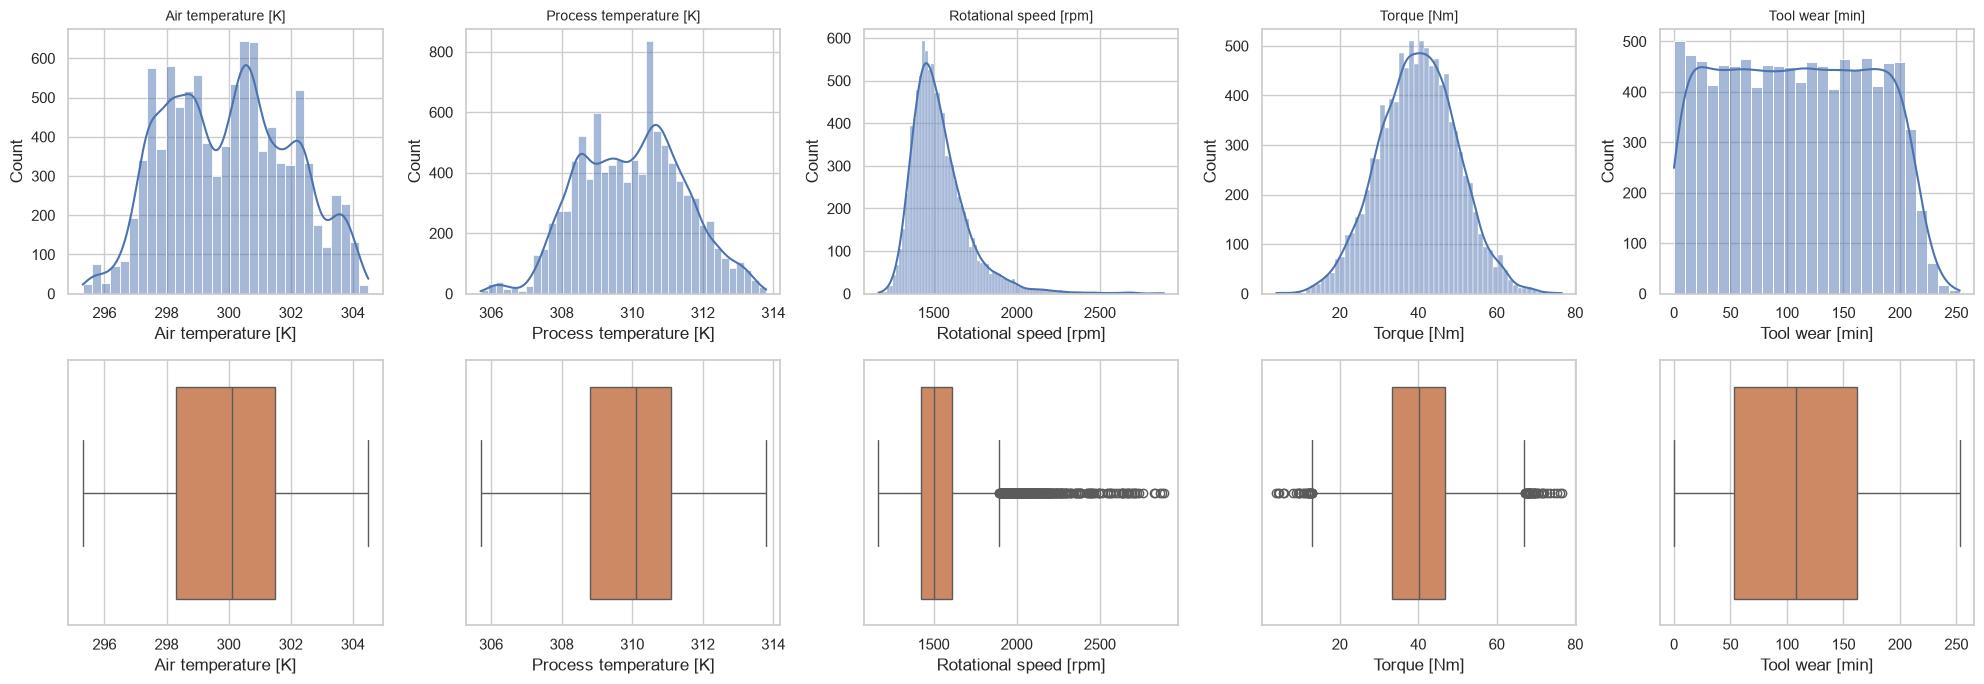

In [22]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, col in enumerate(NUM_COLS):
    sns.histplot(df[col], kde=True, ax=axes[0, i], color="#4c72b0")
    axes[0, i].set_title(col, fontsize=10)
    sns.boxplot(x=df[col], ax=axes[1, i], color="#dd8452")
plt.tight_layout(); plt.show()

In [23]:
def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    mask = (s < lo) | (s > hi)
    return lo, hi, mask

rows = []
for col in NUM_COLS:
    lo, hi, m = iqr_outliers(df[col])
    rows.append({"feature": col, "lower_fence": round(lo, 2), "upper_fence": round(hi, 2),
                 "n_outliers": int(m.sum()), "pct": round(m.mean() * 100, 2),
                 "failure_rate_in_outliers_%": round(df.loc[m, TARGET].mean() * 100, 2) if m.any() else np.nan})
outlier_report = pd.DataFrame(rows)
outlier_report

,feature,lower_fence,upper_fence,n_outliers,pct,failure_rate_in_outliers_%
0,Air temperature [K],293.50,306.30,0,0.00,NaN
1,Process temperature [K],305.35,314.55,0,0.00,NaN
2,Rotational speed [rpm],1139.50,1895.50,418,4.18,8.37
3,Torque [Nm],12.80,67.20,69,0.69,89.86
4,Tool wear [min],-110.50,325.50,0,0.00,NaN


**How to read this:** if the failure rate *inside* the outliers is much higher than the overall rate (~3.4%), those "outliers" are probably **real fault signals**, not noise — so removing them would delete exactly what a maintenance model needs to learn. Here, outliers are reported but **not** removed.

In [24]:
# Physical sanity: process temperature should be hotter than air temperature
df["_temp_diff"] = df["Process temperature [K]"] - df["Air temperature [K]"]
print("Rows where process temp <= air temp:", int((df["_temp_diff"] <= 0).sum()))
print(df["_temp_diff"].describe().round(2))
df = df.drop(columns="_temp_diff")

Rows where process temp <= air temp: 0
count    10000.0
mean        10.0
std          1.0
min          7.6
25%          9.3
50%          9.8
75%         11.0
max         12.1
Name: _temp_diff, dtype: float64


## 8. Correlation & leakage check

**Analogy:** giving the model `TWF/HDF/PWF/OSF/RNF` to predict `Machine failure` is like handing a student the answer key with the exam. Scores will look amazing and mean nothing.

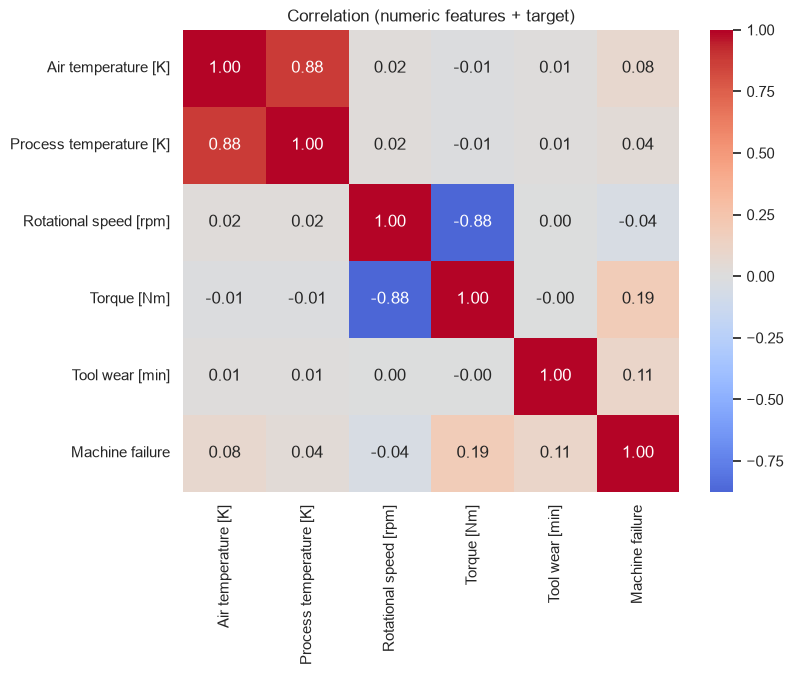

In [25]:
corr_cols = NUM_COLS + [TARGET]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation (numeric features + target)")
plt.show()

In [26]:
# Leakage: how strongly do failure-mode flags determine the target?
leak = df[FAILURE_MODES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False)
print("Correlation of failure-mode flags with target:")
print(leak.round(3))
print("\n-> These columns are consequences of the failure, NOT inputs. Exclude them from the feature set.")

Correlation of failure-mode flags with target:
HDF    0.576
OSF    0.531
PWF    0.523
TWF    0.363
RNF    0.005
Name: Machine failure, dtype: float64

-> These columns are consequences of the failure, NOT inputs. Exclude them from the feature set.


In [27]:
# Multicollinearity: highly correlated feature pairs
pairs = (corr.loc[NUM_COLS, NUM_COLS].abs()
         .where(np.triu(np.ones((len(NUM_COLS), len(NUM_COLS))), k=1).astype(bool))
         .stack().sort_values(ascending=False))
print("Top correlated feature pairs (|r|):")
print(pairs.head(5).round(3))

Top correlated feature pairs (|r|):
Air temperature [K]      Process temperature [K]    0.876
Rotational speed [rpm]   Torque [Nm]                0.875
Air temperature [K]      Rotational speed [rpm]     0.023
Process temperature [K]  Rotational speed [rpm]     0.019
                         Torque [Nm]                0.014
dtype: float64


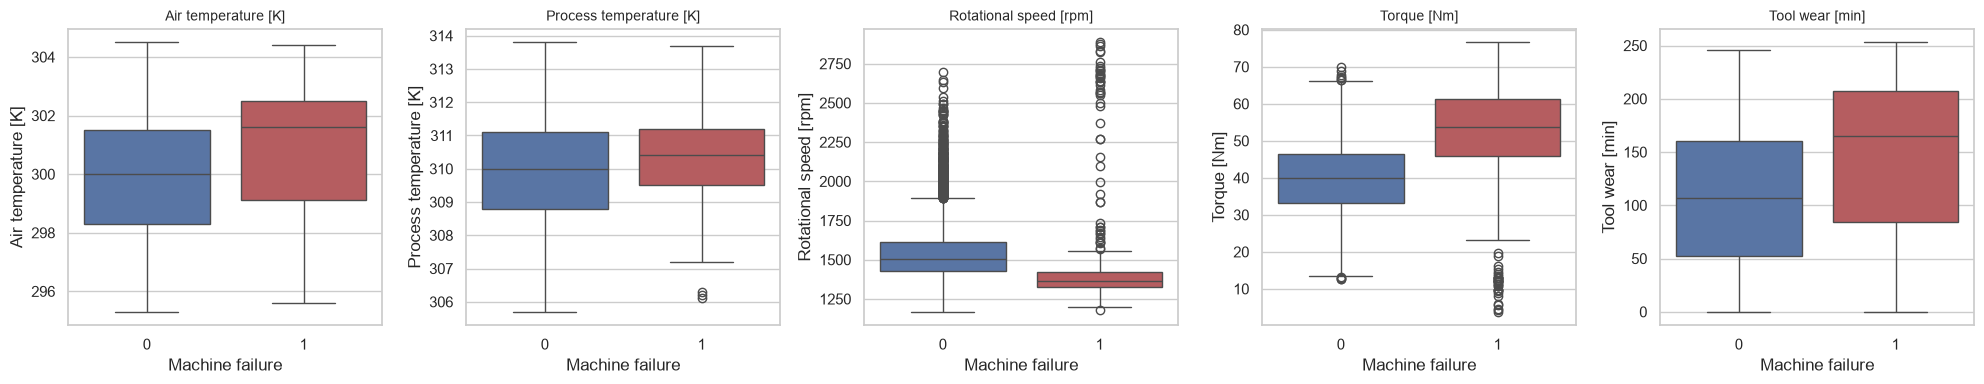

In [28]:
# Feature behaviour by target class
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(x=TARGET, y=col, data=df, ax=ax, palette=["#4c72b0", "#c44e52"])
    ax.set_title(col, fontsize=10)
plt.tight_layout(); plt.show()

## 9. Preprocessing pipeline

Steps: drop identifiers & leakage columns → rename for convenience → **stratified split** → one-hot encode `Type` → scale numeric columns.

**Golden rule (the "exam" analogy again):** the scaler may only *study* the training set. If it peeks at the test set, that is a leak in disguise.

In [29]:
# 9.1 Remove identifiers & leakage columns
df_clean = df.drop(columns=ID_COLS + FAILURE_MODES).copy()

# 9.2 Safe column names (brackets/spaces break many tools)
rename_map = {
    "Air temperature [K]": "air_temp_k",
    "Process temperature [K]": "process_temp_k",
    "Rotational speed [rpm]": "rot_speed_rpm",
    "Torque [Nm]": "torque_nm",
    "Tool wear [min]": "tool_wear_min",
    "Machine failure": "machine_failure",
    "Type": "type",
}
df_clean = df_clean.rename(columns=rename_map)
NUM_F = [rename_map[c] for c in NUM_COLS]
CAT_F = ["type"]
TARGET_N = "machine_failure"

# 9.3 Optional feature engineering (physically motivated). Toggle as needed.
ADD_ENGINEERED = True
if ADD_ENGINEERED:
    df_clean["temp_diff_k"] = df_clean["process_temp_k"] - df_clean["air_temp_k"]
    df_clean["power_w"] = df_clean["torque_nm"] * df_clean["rot_speed_rpm"] * 2 * np.pi / 60
    df_clean["wear_x_torque"] = df_clean["tool_wear_min"] * df_clean["torque_nm"]
    NUM_F = NUM_F + ["temp_diff_k", "power_w", "wear_x_torque"]

print("Final feature columns:", NUM_F + CAT_F)
df_clean.head()

Final feature columns: ['air_temp_k', 'process_temp_k', 'rot_speed_rpm', 'torque_nm', 'tool_wear_min', 'temp_diff_k', 'power_w', 'wear_x_torque', 'type']


,type,air_temp_k,process_temp_k,rot_speed_rpm,torque_nm,tool_wear_min,machine_failure,temp_diff_k,power_w,wear_x_torque
0,M,298.1,308.6,1551,42.8,0,0,10.5,6951.590560,0.0
1,L,298.2,308.7,1408,46.3,3,0,10.5,6826.722724,138.9
2,L,298.1,308.5,1498,49.4,5,0,10.4,7749.387543,247.0
3,L,298.2,308.6,1433,39.5,7,0,10.4,5927.504659,276.5
4,L,298.2,308.7,1408,40.0,9,0,10.5,5897.816608,360.0


In [30]:
# 9.4 Stratified split (keeps the ~3.4% failure rate in every subset)
X = df_clean.drop(columns=TARGET_N)
y = df_clean[TARGET_N]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

split_check = pd.DataFrame({
    "rows": [len(y), len(y_train), len(y_test)],
    "failures": [y.sum(), y_train.sum(), y_test.sum()],
    "failure_rate_%": [round(y.mean()*100, 2), round(y_train.mean()*100, 2), round(y_test.mean()*100, 2)],
}, index=["full", "train", "test"])
split_check

,rows,failures,failure_rate_%
full,10000,339,3.39
train,8000,271,3.39
test,2000,68,3.40


In [31]:
# 9.5 Encode + scale. Fit on TRAIN only, apply to both.
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUM_F),
        ("cat", OneHotEncoder(categories=[["L", "M", "H"]], drop=None, sparse_output=False), CAT_F),
    ],
    verbose_feature_names_out=False,
)

X_train_arr = preprocessor.fit_transform(X_train)
X_test_arr  = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

X_train_proc = pd.DataFrame(X_train_arr, columns=feature_names, index=X_train.index)
X_test_proc  = pd.DataFrame(X_test_arr,  columns=feature_names, index=X_test.index)

print("Train:", X_train_proc.shape, "| Test:", X_test_proc.shape)
X_train_proc.head()

Train: (8000, 11) | Test: (2000, 11)


,air_temp_k,process_temp_k,rot_speed_rpm,torque_nm,tool_wear_min,temp_diff_k,power_w,wear_x_torque,type_L,type_M,type_H
4058,0.998914,0.604282,-0.460607,0.718305,-0.843997,-1.100842,0.852387,-0.621945,0.0,1.0,0.0
1221,-1.505194,-1.153260,-0.775574,0.638456,0.382263,1.299658,0.480363,0.646140,0.0,1.0,0.0
6895,0.498092,1.077466,-1.007654,0.558607,0.460870,0.599512,0.184041,0.689544,0.0,1.0,0.0
9863,-0.553633,-0.139294,-0.709265,1.626586,-0.372359,0.899575,1.898861,0.151247,1.0,0.0,0.0
8711,-1.455112,-1.018064,1.070019,-1.128202,-0.906882,1.399679,-1.001687,-1.016909,1.0,0.0,0.0


In [32]:
# 9.6 Verification: scaled train features should have mean≈0, std≈1; test will be close but not exact (by design)
check = pd.DataFrame({
    "train_mean": X_train_proc[NUM_F].mean().round(3),
    "train_std":  X_train_proc[NUM_F].std().round(3),
    "test_mean":  X_test_proc[NUM_F].mean().round(3),
    "test_std":   X_test_proc[NUM_F].std().round(3),
})
check

,train_mean,train_std,test_mean,test_std
air_temp_k,0.0,1.0,-0.001,1.009
process_temp_k,0.0,1.0,-0.002,1.015
rot_speed_rpm,0.0,1.0,-0.016,0.952
torque_nm,-0.0,1.0,-0.008,0.975
tool_wear_min,-0.0,1.0,0.021,1.003
temp_diff_k,-0.0,1.0,0.000,1.006
power_w,0.0,1.0,-0.013,0.977
wear_x_torque,-0.0,1.0,0.021,1.011


## 10. Export

Saves the cleaned (unscaled) frame plus the processed train/test splits.

In [33]:
import os, joblib
os.makedirs("processed", exist_ok=True)

df_clean.to_csv("processed/ai4i2020_clean.csv", index=False)

train_out = X_train_proc.copy(); train_out[TARGET_N] = y_train.values
test_out  = X_test_proc.copy();  test_out[TARGET_N]  = y_test.values
train_out.to_csv("processed/train_processed.csv", index=False)
test_out.to_csv("processed/test_processed.csv", index=False)

joblib.dump(preprocessor, "processed/preprocessor.joblib")
print("Saved:", os.listdir("processed"))

Saved: ['preprocessor.joblib', 'ai4i2020_clean.csv', 'test_processed.csv', 'train_processed.csv']


## Summary of findings

Fill this in after running the notebook (values come from the outputs above):

| Check | Result | Action taken |
|---|---|---|
| Missing values | see section 2 | none needed / impute if > 0 |
| Duplicate rows / IDs | see section 3 | none needed / drop if > 0 |
| Class balance | see section 4 | stratified split; handle imbalance **only inside training** |
| Label consistency | see section 5 | reported; `DROP_INCONSISTENT` flag available |
| Outliers | see section 7 | kept (likely real fault signals) |
| Leakage | see section 8 | `TWF/HDF/PWF/OSF/RNF` and IDs removed from features |
| Scaling / encoding | section 9 | fit on train only; pipeline saved |